# รันซ้ำให้ครบ 3 ค่าเริ่มต้นสุ่ม · ความกว้าง 32/64 · Baseline CNN 3 ชั้น · 3D

In [1]:
import os
import sys
import json
import time
import shutil
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm import tqdm

# โฟลเดอร์ที่มี split.json / processing_lock.py / augmentation_lock.py (แก้ให้ตรงกับเครื่อง)
SHARED_DIR = "/home/jovyan/Alzheimer's/src/00-shared"
CACHE_DIR = os.path.join(SHARED_DIR, "locked_cache")
sys.path.insert(0, SHARED_DIR)
import processing_lock as PL
import augmentation_lock as AL

print(PL.describe())

processing_lock v1 | hash 22275bfd6b | target (128, 128, 96) | clip p1-99 | order 1 | center (sag,cor,axi) = (64, 64, 48)


In [2]:
with open(os.path.join(SHARED_DIR, "split.json")) as f:
    split = json.load(f)

labels = split["labels"]
train_ids = split["train"]
val_ids = split["val"]
test_ids = split["test"]

print("Train      :", len(train_ids))
print("Validation :", len(val_ids))
print("Test       :", len(test_ids), "(ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)")

Train      : 163
Validation : 35
Test       : 36 (ไฟล์นี้ไม่ใช้ test จนกว่าจะถึงเซลล์สุดท้าย)


## ตั้งค่า (ปรับตรงนี้)

In [3]:
MODE = "3D"            # "3D" / "2.5D" / "2D"
PRETRAINED = False       # โมเดลนี้สร้างจากศูนย์ ไม่มี pretrained

# ค่าเทรน (ไม่ใส่ regularization เพื่อเป็นจุดเริ่มต้นที่ธรรมดาที่สุด)
LR = 0.001
DROPOUT = 0.0
WEIGHT_DECAY = 0.0
LABEL_SMOOTHING = 0.0
BATCH_SIZE = 8
EPOCHS = 200
SEEDS = [1334, 42, 2026]
NUM_WORKERS = 4          # ถ้า error เรื่อง shared memory ให้ใส่ 0
CHECKPOINT_EVERY = 10      # เซฟจุดต่อทุกกี่ epoch (ไว้ให้เริ่มต่อได้ถ้าหลุดกลางทาง)

# augmentation ที่ล็อกแล้ว (ผลจากการทดลองหมุน / gamma / noise)
BASE_ROTATE_DEG = 10      # หมุน ±10 องศา
BASE_GAMMA_D = 0.2        # gamma d = 0.2 (γ 0.8 – 1.2)
NOISE_TYPE = "gaussian"   # ไม่ได้ใช้ (noise ปิด) แต่โค้ดเดียวกับไฟล์อื่นต้องมี

# รายการการทดลอง: ชื่อ -> augmentation (ล็อก) + โครงสร้างโมเดล (MODEL)
AUG = {"ROTATE_DEG": BASE_ROTATE_DEG, "GAMMA_D": BASE_GAMMA_D, "NOISE_STD": 0.0}
EXPERIMENTS = {
    "bn":          {**AUG, "MODEL": {"width": 8,  "kernel": 3, "batchnorm": True}},    # ตัวควบคุม (รันไว้แล้ว ข้ามอัตโนมัติ)
    "bn_width_32": {**AUG, "MODEL": {"width": 32, "kernel": 3, "batchnorm": True}},    # channel 32/64/128 มี BN
    "width_64":    {**AUG, "MODEL": {"width": 64, "kernel": 3, "batchnorm": False}},   # channel 64/128/256 ไม่มี BN
    "bn_width_64": {**AUG, "MODEL": {"width": 64, "kernel": 3, "batchnorm": True}},    # channel 64/128/256 มี BN
}
RUN_LIST = ["bn", "bn_width_32", "width_64", "bn_width_64"]
GRID_NAMES = []
GRID_OPTS = []

EXP_DIR = "runs_baseline_3D"                 # โฟลเดอร์เดียวกับ baseline 3D เพื่อใช้ผลเดิมต่อ
REUSE_FROM = {}
os.makedirs(EXP_DIR, exist_ok=True)
print("RUN_LIST:", RUN_LIST, "| seed:", SEEDS)


RUN_LIST: ['bn', 'bn_width_32', 'width_64', 'bn_width_64'] | seed: [1334, 42, 2026]


## ฟังก์ชันพื้นฐาน และดูความคืบหน้า

In [4]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


# ---------- ดูความคืบหน้า: อ่านจากไฟล์ progress ของแต่ละการทดลอง (รันเซลล์นี้ซ้ำได้ตลอด แม้เทรนอยู่) ----------
def show_progress():
    rows = []
    for name in RUN_LIST:
        for seed in SEEDS:
            p = os.path.join(EXP_DIR, name, "progress", f"seed{seed}.json")
            if os.path.exists(p):
                d = json.load(open(p))
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": d["status"],
                             "epoch": f"{d['epoch']}/{d['epochs']}", "best_epoch": d["best_epoch"],
                             "best combo": round(d["best_combo"], 4), "val AUC ล่าสุด": round(d["last_val_auc"], 4),
                             "นาทีที่ใช้": d["minutes"], "อัปเดตล่าสุด": d["updated"]})
            else:
                rows.append({"การทดลอง": name, "seed": seed, "สถานะ": "ยังไม่เริ่ม", "epoch": "-", "best_epoch": "-",
                             "best combo": "-", "val AUC ล่าสุด": "-", "นาทีที่ใช้": "-", "อัปเดตล่าสุด": "-"})
    table = pd.DataFrame(rows)
    done = int((table["สถานะ"] == "เสร็จแล้ว").sum())
    print(f"เสร็จแล้ว {done} / {len(table)} รัน")
    display(table)

show_progress()

cuda
เสร็จแล้ว 6 / 12 รัน


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด
0,bn,1334,เสร็จแล้ว,200/200,115,0.7313,0.78,14.5,2026-10-27 05:11:53
1,bn,42,เสร็จแล้ว,200/200,179,0.7581,0.7567,9.0,2026-10-27 05:20:54
2,bn,2026,เสร็จแล้ว,200/200,169,0.7431,0.74,9.0,2026-10-27 05:29:55
3,bn_width_32,1334,เสร็จแล้ว,200/200,104,0.7333,0.7167,23.7,2026-10-29 09:29:40
4,bn_width_32,42,กำลังรัน,122/200,101,0.7475,0.74,13.2,2026-11-20 15:07:18
5,bn_width_32,2026,ยังไม่เริ่ม,-,-,-,-,-,-
6,width_64,1334,เสร็จแล้ว,200/200,1,0.2725,0.5,24.0,2026-10-29 09:53:38
7,width_64,42,ยังไม่เริ่ม,-,-,-,-,-,-
8,width_64,2026,ยังไม่เริ่ม,-,-,-,-,-,-
9,bn_width_64,1334,เสร็จแล้ว,200/200,104,0.7667,0.7467,27.3,2026-10-29 10:20:58


## ข้อมูล และ augmentation

In [5]:
try:
    PL.load_locked(val_ids, CACHE_DIR, verbose=False)
except FileNotFoundError:
    print("ยังไม่มี cache กำลังสร้าง (ครั้งแรกใช้เวลาสักพัก)")
    PL.build_cache(train_ids + val_ids + test_ids, cache_dir=CACHE_DIR)

if MODE == "3D":
    make_kw = {}
else:
    make_kw = {"out_size": 128}


def augment_intensity(x, seed, epoch, sid, gamma_d, noise_std, noise_type):
    """Gamma และ Noise (ทำหลังหมุนและตัด slice แล้ว) ค่าสุ่มผูกกับ (seed, epoch, คน) ทำซ้ำได้ทุกรอบ"""
    if gamma_d == 0 and noise_std == 0:
        return x                                    # ไม่ทำอะไร: ภาพคงเดิมทุกค่า

    x = np.clip(x, 0, 1)                            # ภาพ normalize เป็น [0, 1] แล้ว

    # ---- Gamma: x ยกกำลัง g โดย g สุ่มใน (1 - d, 1 + d) ค่าเดียวต่อคนต่อ epoch ----
    if gamma_d > 0:
        g = np.random.default_rng([seed, epoch, sid, 4]).uniform(1 - gamma_d, 1 + gamma_d)
        x = x ** g                                  # 0 ยังเป็น 0, 1 ยังเป็น 1

    # ---- Noise: เติมเฉพาะในเนื้อสมอง (voxel ที่ > 0) พื้นหลังที่ตัดทิ้งแล้วไม่เติม ----
    if noise_std > 0:
        rng = np.random.default_rng([seed, epoch, sid, 6])
        brain = x > 0
        n1 = rng.normal(0, noise_std, x.shape)
        if noise_type == "rician":
            n2 = rng.normal(0, noise_std, x.shape)
            noisy = np.sqrt((x + n1) ** 2 + n2 ** 2)    # Rician: ขนาดของค่าเชิงซ้อนที่มี noise
        else:
            noisy = x + n1                              # Gaussian
        x = np.where(brain, np.clip(noisy, 0, 1), x)

    return x.astype(np.float32)


class MRIDataset(Dataset):
    # train=True: ใช้ augmentation ตามค่าที่ตั้งไว้ในตัว dataset / train=False: ไม่ทำอะไรกับภาพ
    def __init__(self, ids, train):
        self.ids = list(ids)
        self.volumes = PL.load_locked(self.ids, CACHE_DIR, verbose=False)
        self.y = [labels[s] for s in self.ids]
        self.train = train

        # ค่า augmentation (ตั้งใหม่ทุกครั้งก่อนเทรนแต่ละการทดลอง)
        self.seed = 1334
        self.epoch = 1
        self.rotate_deg = 0
        self.gamma_d = 0.0
        self.noise_std = 0.0
        self.noise_type = "gaussian"
        self.p_rotate = 1.0       # ความน่าจะเป็นที่คนนี้ใน epoch นี้จะถูกหมุน (1.0 = ทุกครั้ง)
        self.p_gamma = 1.0        # ความน่าจะเป็นที่จะถูกปรับ gamma (สุ่มแยกจากการหมุน)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, i):
        sid = int(self.ids[i])

        # "โยนเหรียญ" ว่าครั้งนี้จะทำ augmentation ไหม ผูกกับ (seed, epoch, คน) ทำซ้ำได้ ไม่ขึ้นกับโมเดล
        do_rotate = do_gamma = True
        if self.train and self.p_rotate < 1:
            do_rotate = np.random.default_rng([self.seed, self.epoch, sid, 8]).random() < self.p_rotate
        if self.train and self.p_gamma < 1:
            do_gamma = np.random.default_rng([self.seed, self.epoch, sid, 9]).random() < self.p_gamma

        angle = 0.0
        if self.train and self.rotate_deg > 0 and do_rotate:
            angle = AL.angle_for(self.seed, self.epoch, sid, self.rotate_deg)

        x = PL.make_input(self.volumes[i], MODE, angle, **make_kw)
        x = np.ascontiguousarray(x, dtype=np.float32)

        if self.train:
            x = augment_intensity(x, self.seed, self.epoch, sid, self.gamma_d if do_gamma else 0.0, self.noise_std, self.noise_type)

        return torch.from_numpy(x), self.y[i]


train_data = MRIDataset(train_ids, train=True)
val_data = MRIDataset(val_ids, train=False)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False)

IN_SHAPE = tuple(val_data[0][0].shape)
print("อินพุตต่อคน:", IN_SHAPE)

อินพุตต่อคน: (1, 128, 128, 96)


## ดูตัวอย่างภาพ

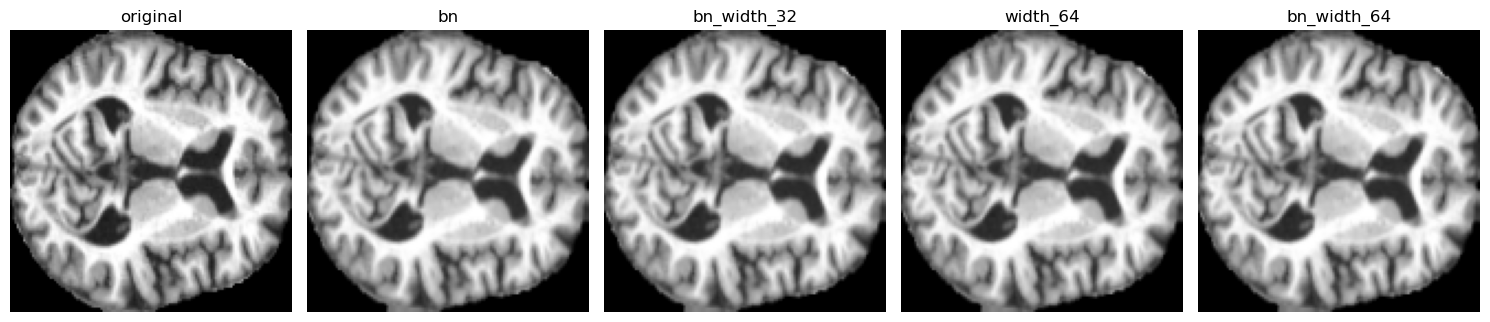

In [6]:
# ดูตัวอย่างภาพของคนแรกใน train ที่แต่ละระดับ (epoch 1, seed แรก) เพื่อเช็กว่า augmentation ทำงานตามที่คิด
prev = MRIDataset(train_ids[:1], train=True)
prev.seed = SEEDS[0]

def axial_slice(x):
    if MODE == "3D":
        return x[0, :, :, x.shape[3] // 2]       # ตัดกลางแกนสุดท้าย (axial)
    return x[-1]                                  # 2D มี 1 ช่อง / 2.5D ช่องสุดท้ายคือ axial

fig, axes = plt.subplots(1, len(RUN_LIST) + 1, figsize=(3 * (len(RUN_LIST) + 1), 3.4))

prev.rotate_deg, prev.gamma_d, prev.noise_std = 0, 0.0, 0.0
prev.p_rotate, prev.p_gamma = 1.0, 1.0
axes[0].imshow(axial_slice(prev[0][0].numpy()), cmap="gray", vmin=0, vmax=1)
axes[0].set_title("original")
axes[0].axis("off")

for k, name in enumerate(RUN_LIST):
    p = EXPERIMENTS[name]
    prev.rotate_deg, prev.gamma_d, prev.noise_std = p["ROTATE_DEG"], p["GAMMA_D"], p["NOISE_STD"]
    prev.noise_type = NOISE_TYPE
    prev.p_rotate, prev.p_gamma = p.get("P_ROTATE", 1.0), p.get("P_GAMMA", 1.0)
    axes[k + 1].imshow(axial_slice(prev[0][0].numpy()), cmap="gray", vmin=0, vmax=1)
    axes[k + 1].set_title(name)
    axes[k + 1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "augmentation_preview.png"), dpi=150)
plt.show()

## โมเดล: CNN 3 ชั้น (3D)

In [7]:
class SimpleCNN(nn.Module):
    # CNN: [Conv -> (BatchNorm) -> ReLU -> MaxPool] x n_layers (ค่าเริ่มต้น 3) -> หัว (GAP หรือ Flatten) -> Linear 2 คลาส
    # 2D / 2.5D ใช้ Conv2d, 3D ใช้ Conv3d (โครงเดียวกัน เปลี่ยนแค่มิติ)
    def __init__(self, in_ch, dim, width=8, kernel=3, batchnorm=False, dropout=0.0, head="gap", in_shape=None, n_layers=3):
        super().__init__()
        Conv = nn.Conv3d if dim == 3 else nn.Conv2d
        BN = nn.BatchNorm3d if dim == 3 else nn.BatchNorm2d
        Pool = nn.MaxPool3d if dim == 3 else nn.MaxPool2d
        GAP = nn.AdaptiveAvgPool3d if dim == 3 else nn.AdaptiveAvgPool2d

        chans = [in_ch] + [width * 2 ** i for i in range(n_layers)]       # จำนวน channel เพิ่มเป็น 2 เท่าทุกชั้น
        layers = []
        for i in range(n_layers):
            layers.append(Conv(chans[i], chans[i + 1], kernel_size=kernel, padding=kernel // 2, bias=not batchnorm))
            if batchnorm:
                layers.append(BN(chans[i + 1]))
            layers.append(nn.ReLU(inplace=True))
            layers.append(Pool(2))
        self.features = nn.Sequential(*layers)
        # หัวโมเดล: "gap" = เฉลี่ยทั้ง feature map เหลือ 1 ค่าต่อ channel / "flatten" = เอาทุกค่ามาเรียงต่อกัน
        self.gap = GAP(1) if head == "gap" else nn.Identity()
        self.flatten = nn.Flatten()
        if head == "gap":
            n_feat = chans[-1]
        else:
            with torch.no_grad():
                n_feat = self.features(torch.zeros(1, in_ch, *in_shape)).numel()
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(n_feat, 2)

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(self.gap(x))
        return self.fc(self.dropout(x))


DIM = 3 if MODE == "3D" else 2

def make_model(m):
    # m = ค่าโครงสร้างของการทดลองนั้น (EXPERIMENTS[ชื่อ]["MODEL"])
    return SimpleCNN(IN_SHAPE[0], DIM, m["width"], m["kernel"], m["batchnorm"], m.get("dropout", DROPOUT),
                     head=m.get("head", "gap"), in_shape=IN_SHAPE[1:], n_layers=m.get("layers", 3))


# ดูโมเดลทีละชั้น + จำนวน parameter ของการทดลองแรกใน RUN_LIST
_m = make_model(EXPERIMENTS[RUN_LIST[0]]["MODEL"]).eval()
_x = torch.zeros(1, *IN_SHAPE)
print(f"{'input':8s}", tuple(_x.shape[1:]))
with torch.no_grad():
    k = 0
    for layer in _m.features:
        _x = layer(_x)
        if isinstance(layer, (nn.MaxPool2d, nn.MaxPool3d)):
            k += 1
            print(f"{'layer ' + str(k):8s}", tuple(_x.shape[1:]))
print("ฟีเจอร์ที่เข้า Linear:", _m.fc.in_features, "| หัว:", EXPERIMENTS[RUN_LIST[0]]["MODEL"].get("head", "gap"))
print("จำนวน parameter:", f"{sum(q.numel() for q in _m.parameters()):,}")
del _m, _x

input    (1, 128, 128, 96)
layer 1  (8, 64, 64, 48)
layer 2  (16, 32, 32, 24)
layer 3  (32, 16, 16, 12)
ฟีเจอร์ที่เข้า Linear: 32 | หัว: gap
จำนวน parameter: 17,674


## เทรน (ทีละการทดลอง ทีละ seed)

In [8]:
def evaluate(model, loader, criterion):
    # วัดผลบน loader (val) ไม่แตะน้ำหนัก
    model.eval()
    running_loss = 0
    probs, preds, trues = [], [], []

    with torch.no_grad():
        for images, y in loader:
            images = images.to(device)
            y = y.to(device)

            outputs = model(images)
            running_loss += criterion(outputs, y).item()

            probs.extend(torch.softmax(outputs, dim=1)[:, 1].cpu().numpy())
            preds.extend(outputs.argmax(1).cpu().numpy())
            trues.extend(y.cpu().numpy())

    tn, fp, fn, tp = confusion_matrix(trues, preds, labels=[0, 1]).ravel()
    return {
        "loss": running_loss / len(loader),
        "AUC": float(roc_auc_score(trues, probs)),
        "Accuracy": float(accuracy_score(trues, preds)),
        "F1": float(f1_score(trues, preds, zero_division=0)),
        "Sensitivity": float(tp / (tp + fn)) if (tp + fn) > 0 else 0.0,   # AD ที่ทายถูก / AD ทั้งหมด
        "Specificity": float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0,   # Normal ที่ทายถูก / Normal ทั้งหมด
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }


def write_progress(path, name, seed, status, epoch, best_epoch, best_combo, last_val_auc, minutes):
    d = {"name": name, "seed": seed, "status": status, "epoch": epoch, "epochs": EPOCHS,
         "best_epoch": best_epoch, "best_combo": float(best_combo), "last_val_auc": float(last_val_auc),
         "minutes": round(minutes, 1), "updated": time.strftime("%Y-%m-%d %H:%M:%S")}
    json.dump(d, open(path, "w"), indent=1)


def train_one_run(NAME, SEED):
    p = EXPERIMENTS[NAME]
    CONFIG = {"mode": MODE, "pretrained": PRETRAINED, "model": p["MODEL"], "lr": p.get("LR", LR), "dropout": DROPOUT,
              "weight_decay": WEIGHT_DECAY, "label_smoothing": LABEL_SMOOTHING,
              "rotate_deg": p["ROTATE_DEG"], "gamma_d": p["GAMMA_D"], "noise_std": p["NOISE_STD"],
              "noise_type": (NOISE_TYPE if p["NOISE_STD"] > 0 else "gaussian"), "batch_size": p.get("BATCH", BATCH_SIZE), "epochs": EPOCHS}
    if "OPT" in p or "WD" in p or "LS" in p:      # ใส่เฉพาะเมื่อกำหนด เพื่อให้ผลเดิมที่รันไว้ก่อนหน้ายังใช้ต่อได้
        CONFIG["weight_decay"], CONFIG["optimizer"] = p.get("WD", WEIGHT_DECAY), p.get("OPT", "adamw")
        CONFIG["label_smoothing"] = p.get("LS", LABEL_SMOOTHING)
    if p.get("P_ROTATE", 1.0) < 1 or p.get("P_GAMMA", 1.0) < 1:      # ใส่เฉพาะเมื่อ p < 1 เพื่อให้ผลที่รันที่ p = 100% ไว้ก่อนหน้ายังใช้ต่อได้
        CONFIG["p_rotate"], CONFIG["p_gamma"] = p.get("P_ROTATE", 1.0), p.get("P_GAMMA", 1.0)

    # โฟลเดอร์ของการทดลองนี้: results = ผล (.json) / models = น้ำหนัก (.pt) / progress = ความคืบหน้า / figures = กราฟ
    base = os.path.join(EXP_DIR, NAME)
    for sub in ("results", "models", "progress", "figures"):
        os.makedirs(os.path.join(base, sub), exist_ok=True)
    json_path = os.path.join(base, "results", f"seed{SEED}.json")
    best_pt = os.path.join(base, "models", f"seed{SEED}_best.pt")
    last_pt = os.path.join(base, "models", f"seed{SEED}_last.pt")       # จุดเซฟระหว่างเทรน (ลบเมื่อจบ)
    prog_path = os.path.join(base, "progress", f"seed{SEED}.json")

    # ถ้าเคยรันการตั้งค่านี้แล้วในไฟล์อื่น (REUSE_FROM) และตั้งค่าเหมือนกันทุกอย่าง ให้คัดลอกผลมาใช้ ไม่ต้องเทรนซ้ำ
    if not os.path.exists(json_path) and NAME in REUSE_FROM:
        old_json = os.path.join(REUSE_FROM[NAME], "results", f"seed{SEED}.json")
        old_pt = os.path.join(REUSE_FROM[NAME], "models", f"seed{SEED}_best.pt")
        if os.path.exists(old_json) and os.path.exists(old_pt):
            old = json.load(open(old_json))
            if old["config"] == CONFIG:
                shutil.copy(old_pt, best_pt)
                old["name"] = NAME
                json.dump(old, open(json_path, "w"), indent=1)
                write_progress(prog_path, NAME, SEED, "เสร็จแล้ว", EPOCHS, old["best_epoch"], old["best_combo"],
                               old["history"]["val_auc"][-1], old["minutes"])
                print(f"[{NAME}] seed {SEED}: ใช้ผลที่รันไว้แล้วจาก {REUSE_FROM[NAME]}")

    # ถ้ารันเสร็จแล้ว (และตั้งค่าเหมือนเดิม) ให้ข้าม
    if os.path.exists(json_path) and os.path.exists(best_pt):
        if json.load(open(json_path))["config"] == CONFIG:
            print(f"[{NAME}] seed {SEED}: มีผลแล้ว ข้ามไป")
            return

    print("=" * 60)
    print(f"การทดลอง {NAME} | rotate ±{p['ROTATE_DEG']} (p={p.get('P_ROTATE', 1.0)}) | gamma d={p['GAMMA_D']} (p={p.get('P_GAMMA', 1.0)}) | noise std={p['NOISE_STD']} | SEED = {SEED}")
    print("=" * 60)

    set_seed(SEED)
    model = make_model(p["MODEL"]).to(device)
    print("จำนวน parameter:", f"{sum(q.numel() for q in model.parameters()):,}")

    criterion = nn.CrossEntropyLoss(label_smoothing=p.get("LS", LABEL_SMOOTHING))
    val_criterion = nn.CrossEntropyLoss()      # val loss ไม่ใส่ label smoothing เพื่อเทียบกันได้ทุกชุด
    if p.get("OPT", "adamw") == "adam":
        optimizer = optim.Adam(model.parameters(), lr=p.get("LR", LR), weight_decay=p.get("WD", WEIGHT_DECAY))   # L2 รวมใน gradient
    else:
        optimizer = optim.AdamW(model.parameters(), lr=p.get("LR", LR), weight_decay=p.get("WD", WEIGHT_DECAY))

    # ตั้งค่า augmentation ของ train ตามระดับของการทดลองนี้
    train_data.seed = SEED
    train_data.rotate_deg = p["ROTATE_DEG"]
    train_data.gamma_d = p["GAMMA_D"]
    train_data.noise_std = p["NOISE_STD"]
    train_data.noise_type = NOISE_TYPE
    train_data.p_rotate = p.get("P_ROTATE", 1.0)
    train_data.p_gamma = p.get("P_GAMMA", 1.0)

    names = ["train_loss", "train_acc", "train_f1", "val_loss", "val_acc", "val_f1", "val_auc", "val_sens", "val_spec"]
    hist = {k: [] for k in names}
    best_combo, best_epoch, best_val, best_state = -1, -1, None, None
    start_epoch = 0
    minutes_before = 0.0

    # ถ้ามีจุดเซฟค้างอยู่ (เคยรันแล้วหลุดกลางทาง และตั้งค่าเหมือนเดิม) ให้เริ่มต่อจากจุดนั้น
    if os.path.exists(last_pt):
        ck = torch.load(last_pt, map_location=device, weights_only=False)
        if ck["config"] == CONFIG:
            model.load_state_dict(ck["model"])
            optimizer.load_state_dict(ck["optimizer"])
            hist, best_combo, best_epoch = ck["hist"], ck["best_combo"], ck["best_epoch"]
            best_val, best_state = ck["best_val"], ck["best_state"]
            start_epoch, minutes_before = ck["epoch"], ck["minutes"]
            print(f"เริ่มต่อจาก epoch {start_epoch + 1} (มีจุดเซฟอยู่)")

    t_start = time.time()
    g = torch.Generator()

    for epoch in range(start_epoch, EPOCHS):

        # ---------- train ----------
        train_data.epoch = epoch + 1
        g.manual_seed(SEED * 1000 + epoch)          # ลำดับสลับภาพของแต่ละ epoch ผูกกับ (seed, epoch)
        train_loader = DataLoader(train_data, batch_size=p.get("BATCH", BATCH_SIZE), shuffle=True, generator=g, num_workers=NUM_WORKERS)

        model.train()
        running_loss = 0
        train_preds, train_trues = [], []

        pbar = tqdm(train_loader, desc=f"{NAME} seed {SEED} epoch {epoch+1}/{EPOCHS}", leave=False)
        for images, y in pbar:
            images = images.to(device)
            y = y.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            train_preds.extend(outputs.argmax(1).cpu().numpy())
            train_trues.extend(y.cpu().numpy())
            pbar.set_postfix(loss=loss.item())

        train_loss = running_loss / len(train_loader)
        train_acc = accuracy_score(train_trues, train_preds)
        train_f1 = f1_score(train_trues, train_preds, zero_division=0)

        # ---------- validation (ไม่ทำ augmentation) ----------
        v = evaluate(model, val_loader, val_criterion)

        hist["train_loss"].append(float(train_loss))
        hist["train_acc"].append(float(train_acc))
        hist["train_f1"].append(float(train_f1))
        hist["val_loss"].append(v["loss"])
        hist["val_acc"].append(v["Accuracy"])
        hist["val_f1"].append(v["F1"])
        hist["val_auc"].append(v["AUC"])
        hist["val_sens"].append(v["Sensitivity"])
        hist["val_spec"].append(v["Specificity"])

        # ---------- เลือก epoch ที่ดีที่สุดจาก val: (AUC + F1) / 2 สูงสุด ----------
        combo_score = (v["AUC"] + v["F1"]) / 2
        if combo_score > best_combo:
            best_combo = combo_score
            best_epoch = epoch + 1
            best_val = {k: v[k] for k in ("AUC", "Accuracy", "F1", "Sensitivity", "Specificity", "TN", "FP", "FN", "TP")}
            best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}

        minutes = minutes_before + (time.time() - t_start) / 60
        write_progress(prog_path, NAME, SEED, "กำลังรัน", epoch + 1, best_epoch, best_combo, v["AUC"], minutes)

        if (epoch + 1) % 10 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:3d} | Train Loss {train_loss:.4f} | Val Loss {v['loss']:.4f} | "
                  f"AUC {v['AUC']:.4f} | F1 {v['F1']:.4f} | Sens {v['Sensitivity']:.3f} | Spec {v['Specificity']:.3f}")

        # ---------- เซฟจุดต่อ (ถ้าหลุดกลางทาง รันซ้ำจะเริ่มต่อจากตรงนี้) ----------
        if (epoch + 1) % CHECKPOINT_EVERY == 0 and (epoch + 1) < EPOCHS:
            torch.save({"config": CONFIG, "model": model.state_dict(), "optimizer": optimizer.state_dict(),
                        "hist": hist, "best_combo": best_combo, "best_epoch": best_epoch,
                        "best_val": best_val, "best_state": best_state,
                        "epoch": epoch + 1, "minutes": minutes}, last_pt)

    # ---------- จบ: เก็บน้ำหนัก (.pt) และผล (.json) ----------
    minutes = minutes_before + (time.time() - t_start) / 60
    torch.save(best_state, best_pt)

    result = {
        "name": NAME,
        "seed": SEED,
        "config": CONFIG,
        "best_epoch": best_epoch,
        "best_combo": float(best_combo),
        "val_best": best_val,
        "val_last": {"AUC": hist["val_auc"][-1], "Accuracy": hist["val_acc"][-1], "F1": hist["val_f1"][-1],
                     "Sensitivity": hist["val_sens"][-1], "Specificity": hist["val_spec"][-1]},
        "minutes": round(minutes, 1),
        "history": hist,
    }
    json.dump(result, open(json_path, "w"), indent=1)
    write_progress(prog_path, NAME, SEED, "เสร็จแล้ว", EPOCHS, best_epoch, best_combo, hist["val_auc"][-1], minutes)
    if os.path.exists(last_pt):
        os.remove(last_pt)

    print()
    print(f"[{NAME}] seed {SEED} เสร็จแล้ว best_epoch: {best_epoch} | combo: {best_combo:.4f} | ใช้เวลา {result['minutes']} นาที")
    print()


OOM_LIST = []
for NAME in RUN_LIST:
    for SEED in SEEDS:
        try:
            train_one_run(NAME, SEED)
        except torch.cuda.OutOfMemoryError:
            print(f"[{NAME}] seed {SEED}: หน่วยความจำ GPU ไม่พอ (OOM) ข้ามชุดนี้")
            OOM_LIST.append((NAME, SEED))
            torch.cuda.empty_cache()
            break          # ชุดนี้ OOM ทุก seed ไม่ต้องลองซ้ำ
if OOM_LIST:
    print("ชุดที่ OOM:", OOM_LIST)

show_progress()

[bn] seed 1334: มีผลแล้ว ข้ามไป
[bn] seed 42: มีผลแล้ว ข้ามไป
[bn] seed 2026: มีผลแล้ว ข้ามไป
[bn_width_32] seed 1334: มีผลแล้ว ข้ามไป
การทดลอง bn_width_32 | rotate ±10 (p=1.0) | gamma d=0.2 (p=1.0) | noise std=0.0 | SEED = 42
จำนวน parameter: 278,050
เริ่มต่อจาก epoch 121 (มีจุดเซฟอยู่)


Epoch 130 | Train Loss 0.4757 | Val Loss 2.3031 | AUC 0.7300 | F1 0.6000 | Sens 1.000 | Spec 0.000


Epoch 140 | Train Loss 0.4026 | Val Loss 2.2765 | AUC 0.7733 | F1 0.0000 | Sens 0.000 | Spec 1.000


Epoch 150 | Train Loss 0.4384 | Val Loss 6.4687 | AUC 0.7367 | F1 0.6000 | Sens 1.000 | Spec 0.000


Epoch 160 | Train Loss 0.4748 | Val Loss 1.0906 | AUC 0.7633 | F1 0.2353 | Sens 0.133 | Spec 1.000


Epoch 170 | Train Loss 0.4850 | Val Loss 1.0043 | AUC 0.7200 | F1 0.2353 | Sens 0.133 | Spec 1.000


... (105 outputs left out)

Epoch 180 | Train Loss 0.4126 | Val Loss 2.0778 | AUC 0.7433 | F1 0.6000 | Sens 1.000 | Spec 0.000


Epoch 190 | Train Loss 0.3887 | Val Loss 0.7780 | AUC 0.7333 | F1 0.6857 | Sens 0.800 | Spec 0.600


Epoch 200 | Train Loss 0.4060 | Val Loss 0.5991 | AUC 0.7700 | F1 0.6250 | Sens 0.667 | Spec 0.650

[bn_width_64] seed 2026 เสร็จแล้ว best_epoch: 136 | combo: 0.7451 | ใช้เวลา 27.4 นาที

เสร็จแล้ว 12 / 12 รัน


,การทดลอง,seed,สถานะ,epoch,best_epoch,best combo,val AUC ล่าสุด,นาทีที่ใช้,อัปเดตล่าสุด
0,bn,1334,เสร็จแล้ว,200/200,115,0.7313,0.7800,14.5,2026-10-27 05:11:53
1,bn,42,เสร็จแล้ว,200/200,179,0.7581,0.7567,9.0,2026-10-27 05:20:54
2,bn,2026,เสร็จแล้ว,200/200,169,0.7431,0.7400,9.0,2026-10-27 05:29:55
3,bn_width_32,1334,เสร็จแล้ว,200/200,104,0.7333,0.7167,23.7,2026-10-29 09:29:40
4,bn_width_32,42,เสร็จแล้ว,200/200,177,0.7478,0.7733,21.7,2026-11-20 15:16:37
5,bn_width_32,2026,เสร็จแล้ว,200/200,154,0.7264,0.7367,21.7,2026-11-20 15:38:18
6,width_64,1334,เสร็จแล้ว,200/200,1,0.2725,0.5000,24.0,2026-10-29 09:53:38
7,width_64,42,เสร็จแล้ว,200/200,5,0.3000,0.5000,33.7,2026-11-20 16:12:01
8,width_64,2026,เสร็จแล้ว,200/200,2,0.5650,0.5000,33.7,2026-11-20 16:45:46
9,bn_width_64,1334,เสร็จแล้ว,200/200,104,0.7667,0.7467,27.3,2026-10-29 10:20:58


## ผลสุดท้าย (Validation): Accuracy, F1, AUC, Sensitivity, Specificity

In [9]:
# ---------- อ่านผลทุกการทดลองจากไฟล์ .json (ไม่ต้องเทรนซ้ำ) ----------
def load_runs(name):
    runs = []
    for s in SEEDS:
        p = os.path.join(EXP_DIR, name, "results", f"seed{s}.json")
        if os.path.exists(p):
            runs.append(json.load(open(p)))
    return runs

all_runs = {name: load_runs(name) for name in RUN_LIST}
METRICS = ["AUC", "F1", "Accuracy", "Sensitivity", "Specificity"]

# ตารางต่อ seed
rows = []
for name, runs in all_runs.items():
    for r in runs:
        h = r["history"]
        row = {"การทดลอง": name, "seed": r["seed"], "best_epoch": r["best_epoch"]}
        for m in METRICS:
            row[f"{m} (best)"] = r["val_best"][m]
        row["AUC (epoch สุดท้าย)"] = r["val_last"]["AUC"]
        row["train loss (สุดท้าย)"] = h["train_loss"][-1]
        row["val loss ต่ำสุด"] = min(h["val_loss"])
        row["val loss (สุดท้าย)"] = h["val_loss"][-1]
        rows.append(row)
per_seed = pd.DataFrame(rows)
display(per_seed.round(3))
per_seed.to_csv(os.path.join(EXP_DIR, "summary_per_seed.csv"), index=False)


def mean_sd_table(key):
    # key = "val_best" (epoch ที่เลือกจาก val) หรือ "val_last" (epoch สุดท้าย)
    out = []
    for name, runs in all_runs.items():
        if len(runs) == 0:
            continue
        row = {"การทดลอง": name, "จำนวน seed": len(runs)}
        for m in METRICS:
            vals = [r[key][m] for r in runs]
            sd = np.std(vals, ddof=1) if len(vals) > 1 else float("nan")
            row[m] = f"{np.mean(vals):.3f} ± {sd:.3f}"
        out.append(row)
    return pd.DataFrame(out)


print()
print("ผลสุดท้ายบน Validation: epoch ที่เลือกจาก val ((AUC + F1) / 2 สูงสุด)  mean ± SD ข้าม seed")
table_best = mean_sd_table("val_best")
display(table_best)
table_best.to_csv(os.path.join(EXP_DIR, "summary_best_epoch.csv"), index=False)

print()
print("ผลสุดท้ายบน Validation: epoch สุดท้าย (ไม่ได้เลือก epoch)  mean ± SD ข้าม seed")
table_last = mean_sd_table("val_last")
display(table_last)
table_last.to_csv(os.path.join(EXP_DIR, "summary_last_epoch.csv"), index=False)

,การทดลอง,seed,best_epoch,AUC (best),F1 (best),Accuracy (best),Sensitivity (best),Specificity (best),AUC (epoch สุดท้าย),train loss (สุดท้าย),val loss ต่ำสุด,val loss (สุดท้าย)
0,bn,1334,115,0.757,0.706,0.714,0.800,0.65,0.780,0.425,0.540,0.563
1,bn,42,179,0.773,0.743,0.743,0.867,0.65,0.757,0.468,0.534,0.995
2,bn,2026,169,0.743,0.743,0.743,0.867,0.65,0.740,0.428,0.549,1.222
3,bn_width_32,1334,104,0.767,0.700,0.657,0.933,0.45,0.717,0.328,0.575,2.287
4,bn_width_32,42,177,0.773,0.722,0.714,0.867,0.60,0.773,0.419,0.532,1.583
5,bn_width_32,2026,154,0.750,0.703,0.686,0.867,0.55,0.737,0.450,0.598,1.084
6,width_64,1334,1,0.545,0.000,0.571,0.000,1.00,0.500,0.682,0.690,0.691
7,width_64,42,5,0.600,0.000,0.571,0.000,1.00,0.500,0.683,0.690,0.692
8,width_64,2026,2,0.530,0.600,0.429,1.000,0.00,0.500,0.680,0.689,0.691
9,bn_width_64,1334,104,0.777,0.757,0.743,0.933,0.60,0.747,0.331,0.532,3.621



ผลสุดท้ายบน Validation: epoch ที่เลือกจาก val ((AUC + F1) / 2 สูงสุด)  mean ± SD ข้าม seed


,การทดลอง,จำนวน seed,AUC,F1,Accuracy,Sensitivity,Specificity
0,bn,3,0.758 ± 0.015,0.731 ± 0.021,0.733 ± 0.016,0.844 ± 0.038,0.650 ± 0.000
1,bn_width_32,3,0.763 ± 0.012,0.708 ± 0.012,0.686 ± 0.029,0.889 ± 0.038,0.533 ± 0.076
2,width_64,3,0.558 ± 0.037,0.200 ± 0.346,0.524 ± 0.082,0.333 ± 0.577,0.667 ± 0.577
3,bn_width_64,3,0.766 ± 0.012,0.748 ± 0.010,0.724 ± 0.016,0.956 ± 0.038,0.550 ± 0.050



ผลสุดท้ายบน Validation: epoch สุดท้าย (ไม่ได้เลือก epoch)  mean ± SD ข้าม seed


,การทดลอง,จำนวน seed,AUC,F1,Accuracy,Sensitivity,Specificity
0,bn,3,0.759 ± 0.020,0.618 ± 0.036,0.562 ± 0.059,0.844 ± 0.214,0.350 ± 0.260
1,bn_width_32,3,0.742 ± 0.029,0.254 ± 0.338,0.562 ± 0.044,0.356 ± 0.559,0.717 ± 0.491
2,width_64,3,0.500 ± 0.000,0.000 ± 0.000,0.571 ± 0.000,0.000 ± 0.000,1.000 ± 0.000
3,bn_width_64,3,0.753 ± 0.015,0.408 ± 0.354,0.552 ± 0.115,0.556 ± 0.509,0.550 ± 0.507


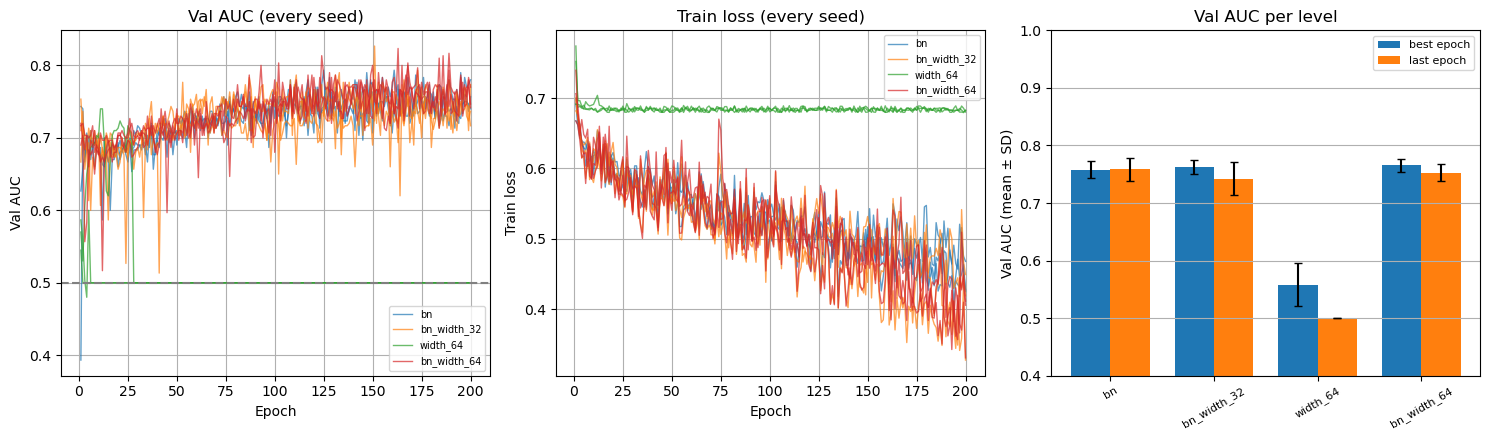

In [10]:
# ---------- กราฟเทียบทุกระดับ ----------
colors = plt.cm.tab10.colors

plt.figure(figsize=(15, 4.5))

# (1) val AUC ต่อ epoch ทุก seed
plt.subplot(1, 3, 1)
for j, (name, runs) in enumerate(all_runs.items()):
    for n, r in enumerate(runs):
        h = r["history"]["val_auc"]
        plt.plot(range(1, len(h) + 1), h, color=colors[j % 10], alpha=0.7, linewidth=1, label=name if n == 0 else None)
plt.axhline(0.5, color="gray", linestyle="--")
plt.xlabel("Epoch")
plt.ylabel("Val AUC")
plt.title("Val AUC (every seed)")
plt.grid(True)
plt.legend(fontsize=7)

# (2) train loss ต่อ epoch ทุก seed
plt.subplot(1, 3, 2)
for j, (name, runs) in enumerate(all_runs.items()):
    for n, r in enumerate(runs):
        h = r["history"]["train_loss"]
        plt.plot(range(1, len(h) + 1), h, color=colors[j % 10], alpha=0.7, linewidth=1, label=name if n == 0 else None)
plt.xlabel("Epoch")
plt.ylabel("Train loss")
plt.title("Train loss (every seed)")
plt.grid(True)
plt.legend(fontsize=7)

# (3) แท่ง: val AUC เฉลี่ย ± SD ของแต่ละระดับ (best epoch เทียบ epoch สุดท้าย)
plt.subplot(1, 3, 3)
names_ok = [n for n, r in all_runs.items() if len(r) > 0]
xpos = np.arange(len(names_ok))
for k, (key, label) in enumerate((("val_best", "best epoch"), ("val_last", "last epoch"))):
    means = [np.mean([r[key]["AUC"] for r in all_runs[n]]) for n in names_ok]
    sds = [np.std([r[key]["AUC"] for r in all_runs[n]], ddof=1) if len(all_runs[n]) > 1 else 0 for n in names_ok]
    plt.bar(xpos + (k - 0.5) * 0.38, means, width=0.38, yerr=sds, capsize=3, label=label)
plt.xticks(xpos, names_ok, rotation=30, fontsize=8)
plt.ylim(0.4, 1.0)
plt.ylabel("Val AUC (mean ± SD)")
plt.title("Val AUC per level")
plt.grid(True, axis="y")
plt.legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(EXP_DIR, "compare_levels.png"), dpi=150)
plt.show()

## สรุปผลความกว้าง (Validation, 3 seed)

In [11]:
def ms(v):
    return f"{np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}" if len(v) > 1 else f"{np.mean(v):.3f}"

LABEL = {"bn": "ความกว้าง 8 มี BN (ตัวควบคุม)", "bn_width_32": "ความกว้าง 32 มี BN",
         "width_64": "ความกว้าง 64 ไม่มี BN", "bn_width_64": "ความกว้าง 64 มี BN"}
rows, raw = [], {}
for name in RUN_LIST:
    runs = all_runs.get(name, [])
    if not runs:
        rows.append({"ชุดทดลอง": LABEL[name], "จำนวน seed": 0, "สถานะ": "ไม่มีผล (OOM หรือยังไม่รัน)"})
        continue
    last10 = [np.mean(r["history"]["val_auc"][-10:]) for r in runs]
    tl10 = [np.mean(r["history"]["train_loss"][-10:]) for r in runs]
    raw[name] = {m: np.mean([r["val_best"][m] for r in runs]) for m in ("AUC", "F1", "Sensitivity", "Specificity")}
    rows.append({"ชุดทดลอง": LABEL[name], "จำนวน seed": len(runs), "สถานะ": "รันได้",
                 "AUC": ms([r["val_best"]["AUC"] for r in runs]),
                 "F1": ms([r["val_best"]["F1"] for r in runs]),
                 "ความไว": ms([r["val_best"]["Sensitivity"] for r in runs]),
                 "ความจำเพาะ": ms([r["val_best"]["Specificity"] for r in runs]),
                 "AUC 10 epoch สุดท้าย": ms(last10),
                 "train loss 10 epoch สุดท้าย": ms(tl10),
                 "best epoch (เฉลี่ย)": round(np.mean([r["best_epoch"] for r in runs]), 1),
                 "นาที/รัน": round(np.mean([r["minutes"] for r in runs]), 1)})
width_tab = pd.DataFrame(rows)
display(width_tab)
width_tab.to_csv(os.path.join(EXP_DIR, "summary_width_3D.csv"), index=False)

if "bn" in raw:
    print("\nเทียบกับ ความกว้าง 8 มี BN (ตัวควบคุม):")
    for name in RUN_LIST:
        if name == "bn" or name not in raw:
            continue
        d = {m: raw[name][m] - raw["bn"][m] for m in raw[name]}
        print(f"{LABEL[name]}: ΔAUC {d['AUC']:+.3f} ({'เกิน' if abs(d['AUC']) > 0.01 else 'ไม่เกิน'} 0.01) | "
              f"ΔF1 {d['F1']:+.3f} ({'เกิน' if abs(d['F1']) > 0.02 else 'ไม่เกิน'} 0.02) | "
              f"Δความไว {d['Sensitivity'] * 15:+.1f} คน (จาก 15) | Δความจำเพาะ {d['Specificity'] * 20:+.1f} คน (จาก 20)")

,ชุดทดลอง,จำนวน seed,สถานะ,AUC,F1,ความไว,ความจำเพาะ,AUC 10 epoch สุดท้าย,train loss 10 epoch สุดท้าย,best epoch (เฉลี่ย),นาที/รัน
0,ความกว้าง 8 มี BN (ตัวควบคุม),3,รันได้,0.758 ± 0.015,0.731 ± 0.021,0.844 ± 0.038,0.650 ± 0.000,0.749 ± 0.008,0.460 ± 0.021,154.3,10.8
1,ความกว้าง 32 มี BN,3,รันได้,0.763 ± 0.012,0.708 ± 0.012,0.889 ± 0.038,0.533 ± 0.076,0.741 ± 0.006,0.416 ± 0.046,145.0,22.4
2,ความกว้าง 64 ไม่มี BN,3,รันได้,0.558 ± 0.037,0.200 ± 0.346,0.333 ± 0.577,0.667 ± 0.577,0.500 ± 0.000,0.683 ± 0.001,2.7,30.5
3,ความกว้าง 64 มี BN,3,รันได้,0.766 ± 0.012,0.748 ± 0.010,0.956 ± 0.038,0.550 ± 0.050,0.756 ± 0.007,0.403 ± 0.022,135.3,28.1



เทียบกับ ความกว้าง 8 มี BN (ตัวควบคุม):
ความกว้าง 32 มี BN: ΔAUC +0.006 (ไม่เกิน 0.01) | ΔF1 -0.022 (เกิน 0.02) | Δความไว +0.7 คน (จาก 15) | Δความจำเพาะ -2.3 คน (จาก 20)
ความกว้าง 64 ไม่มี BN: ΔAUC -0.199 (เกิน 0.01) | ΔF1 -0.531 (เกิน 0.02) | Δความไว -7.7 คน (จาก 15) | Δความจำเพาะ +0.3 คน (จาก 20)
ความกว้าง 64 มี BN: ΔAUC +0.008 (ไม่เกิน 0.01) | ΔF1 +0.017 (ไม่เกิน 0.02) | Δความไว +1.7 คน (จาก 15) | Δความจำเพาะ -2.0 คน (จาก 20)


## กราฟ 2x2 ของแต่ละ seed

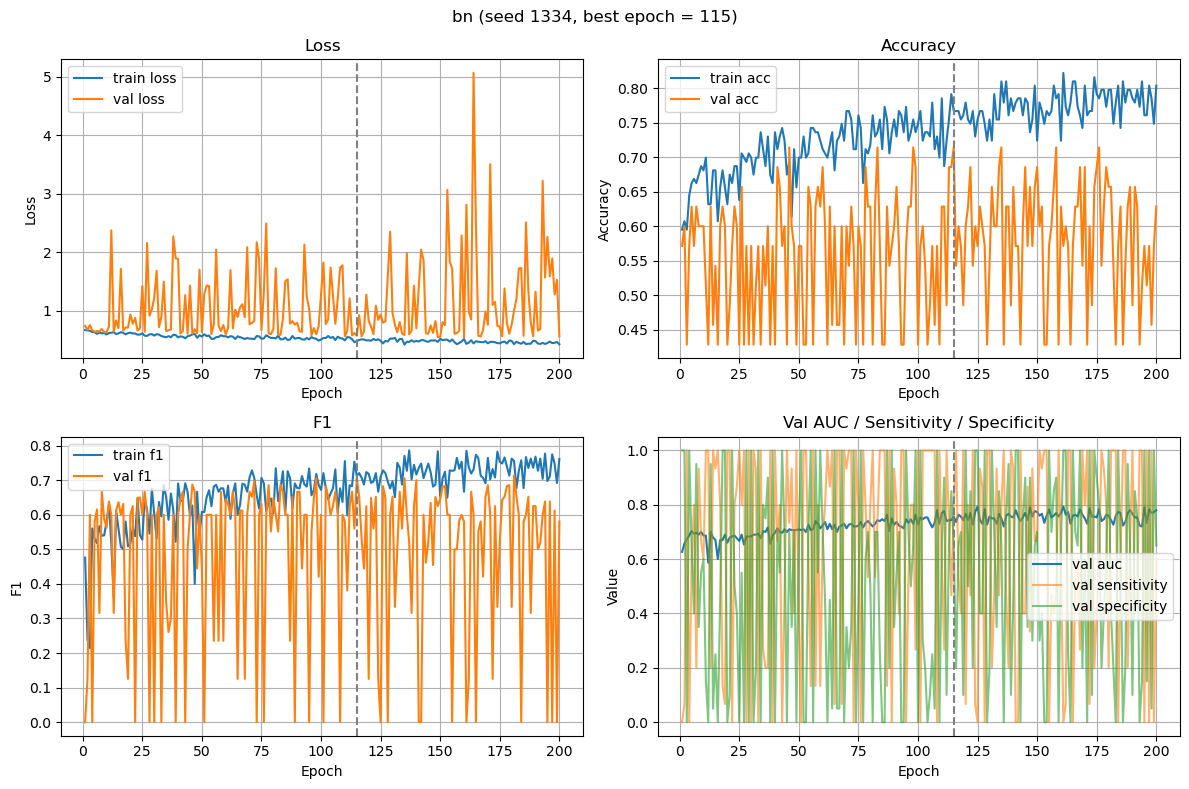

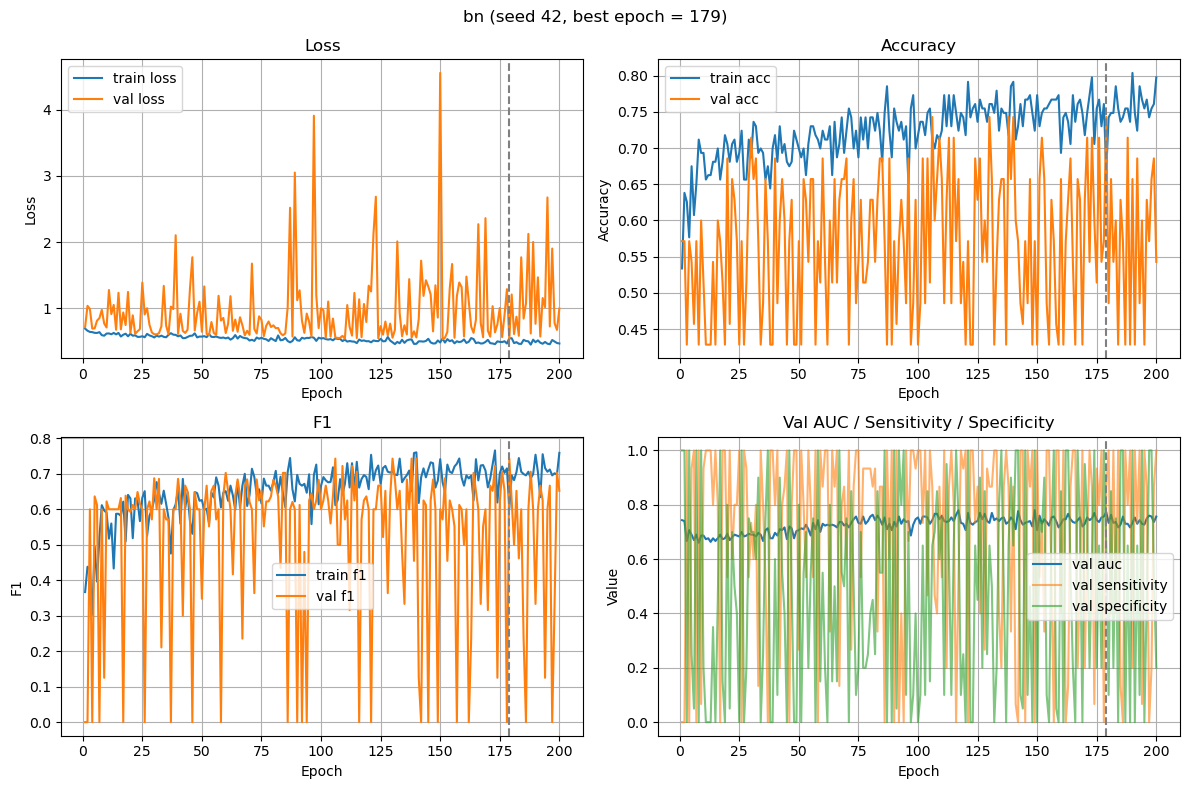

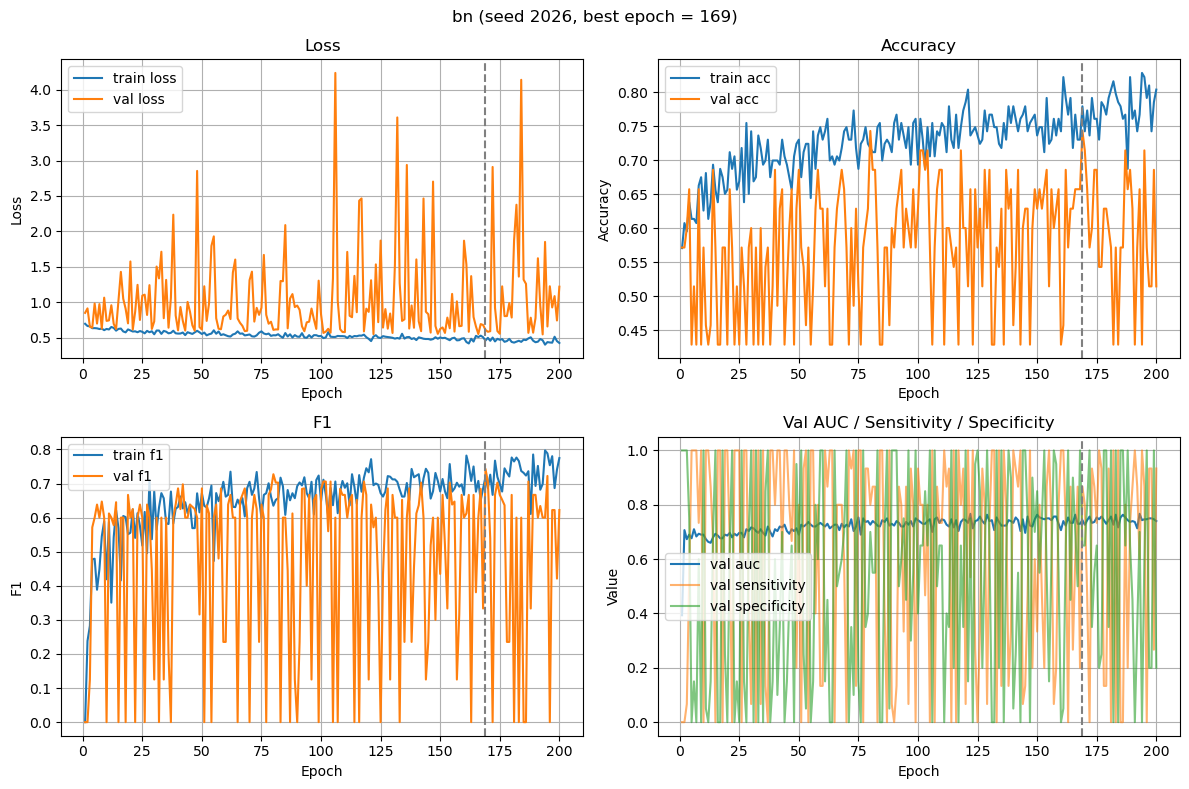

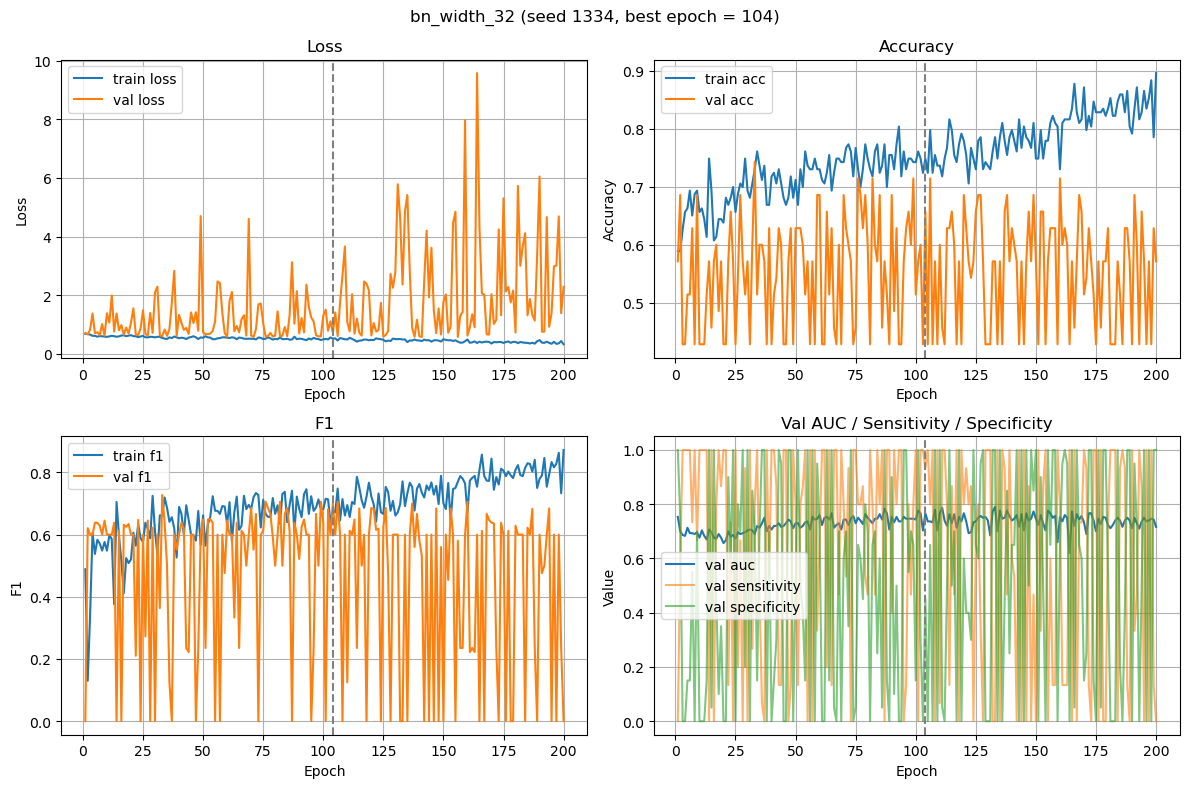

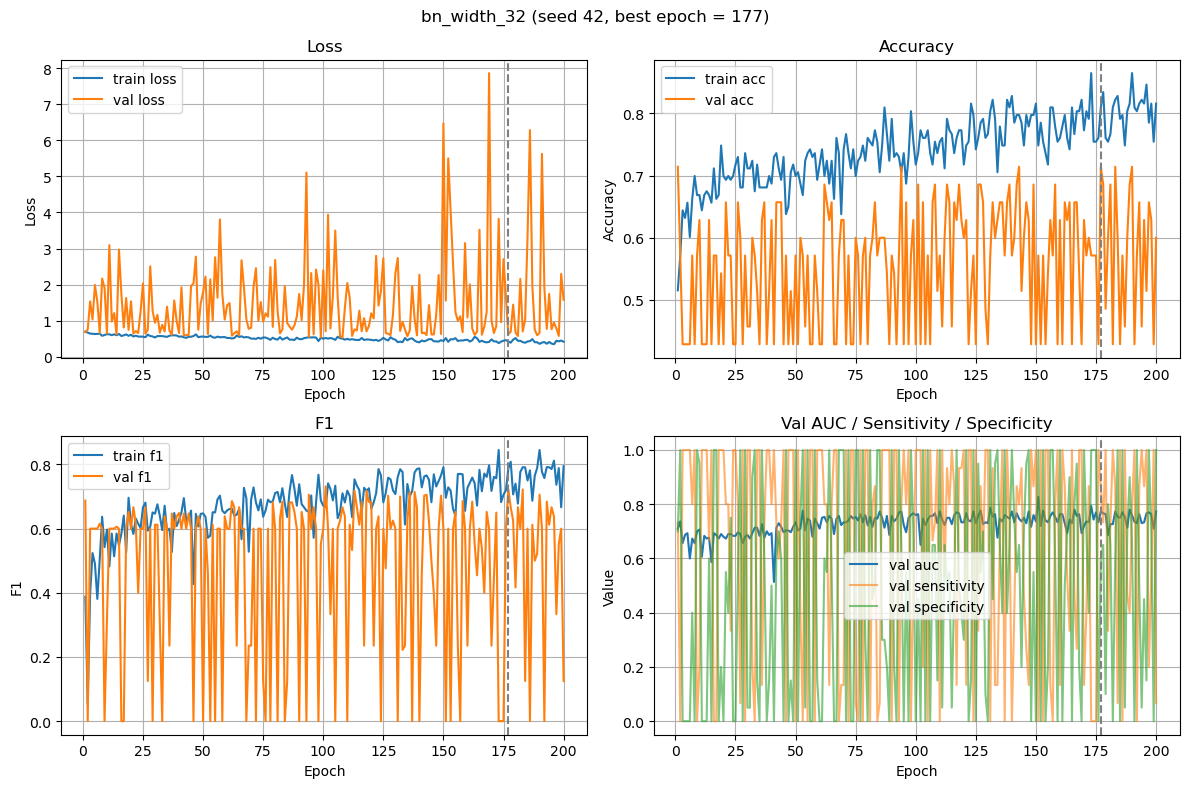

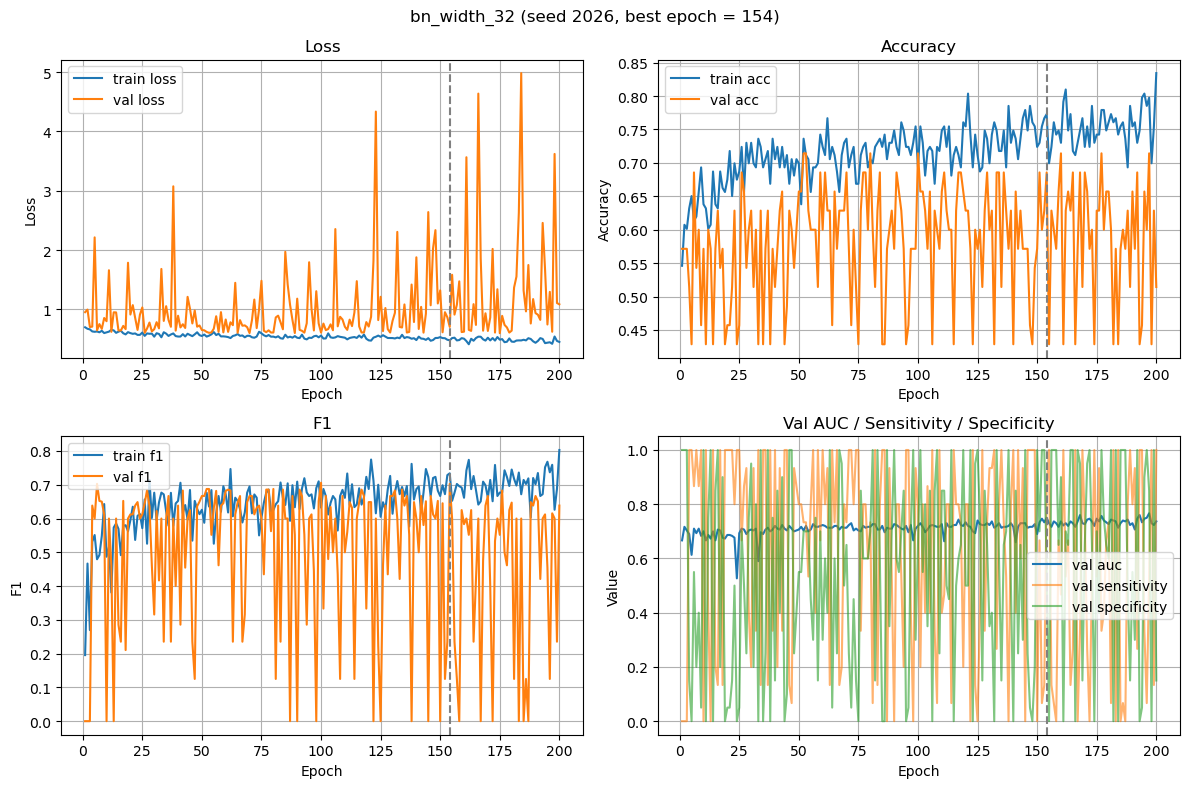

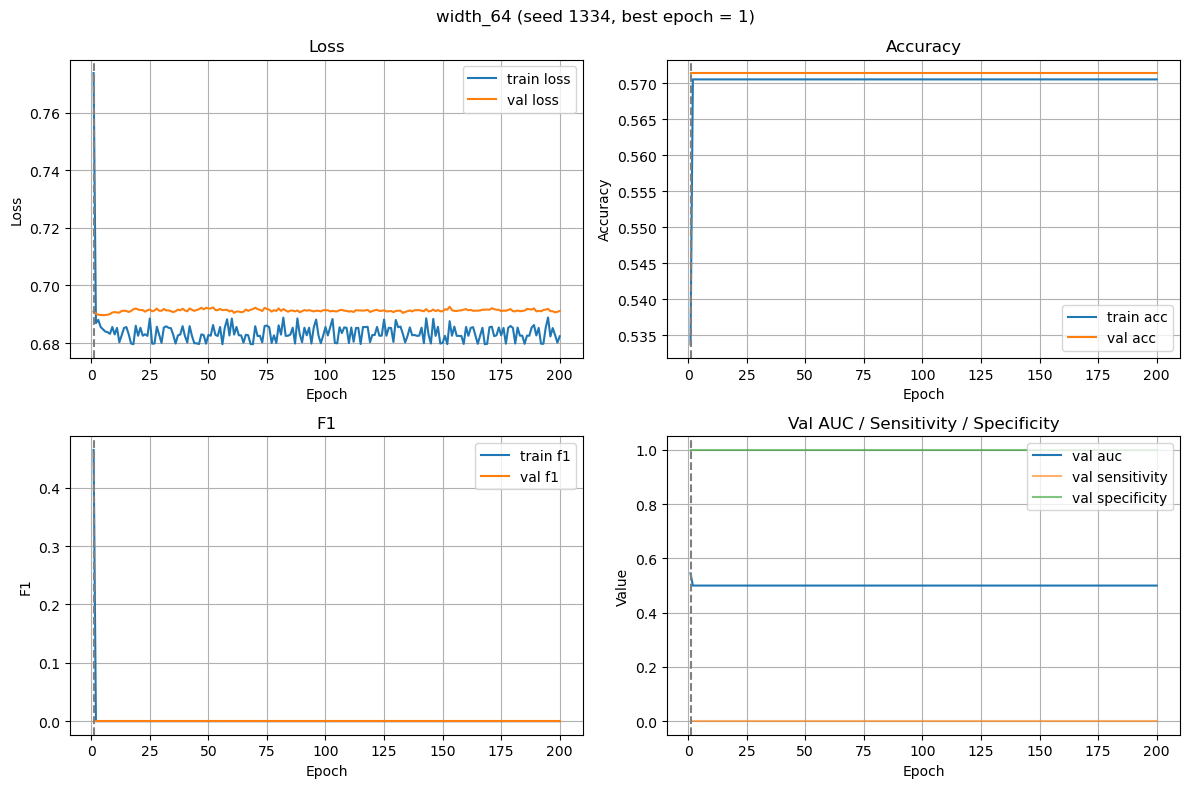

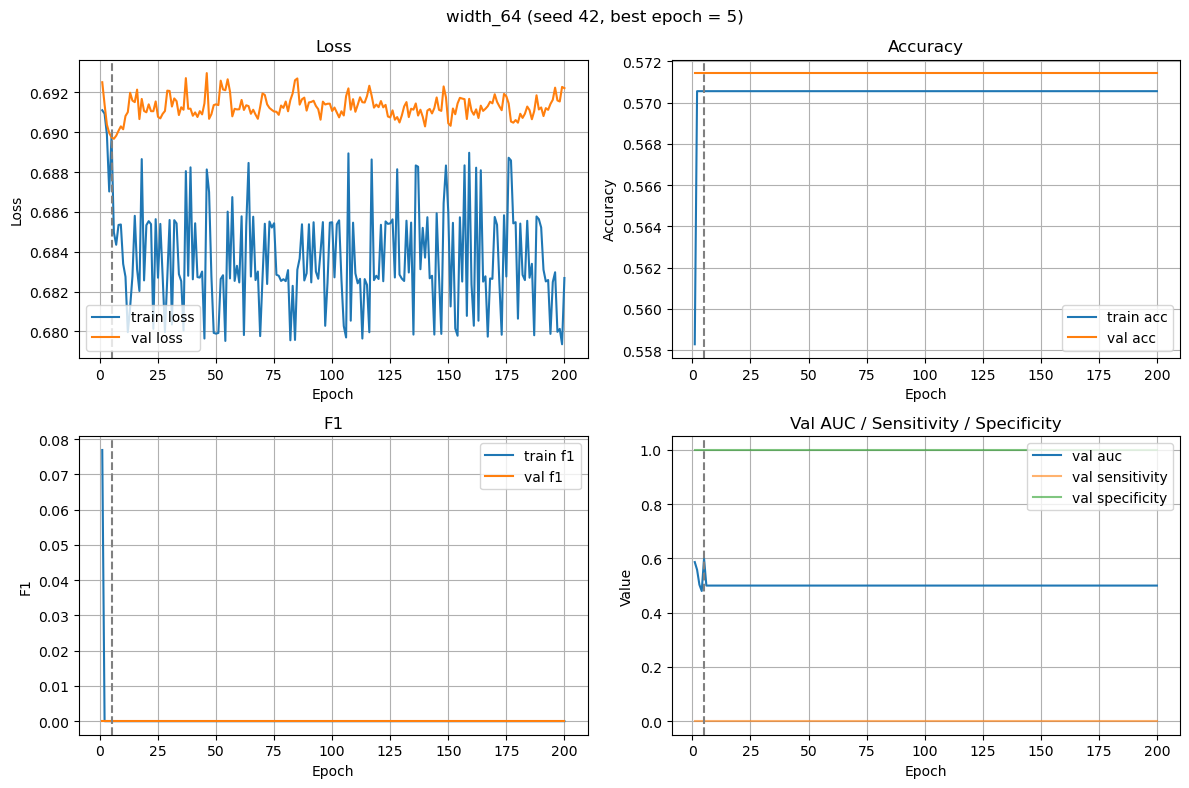

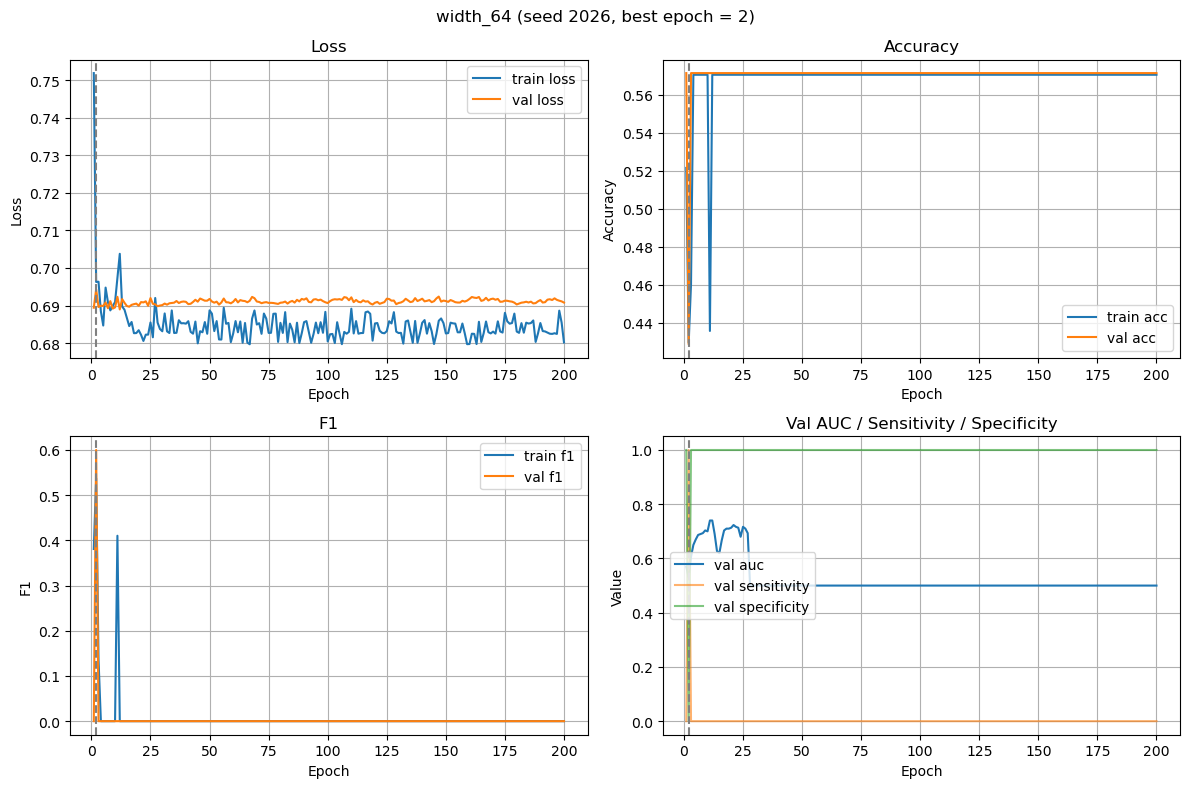

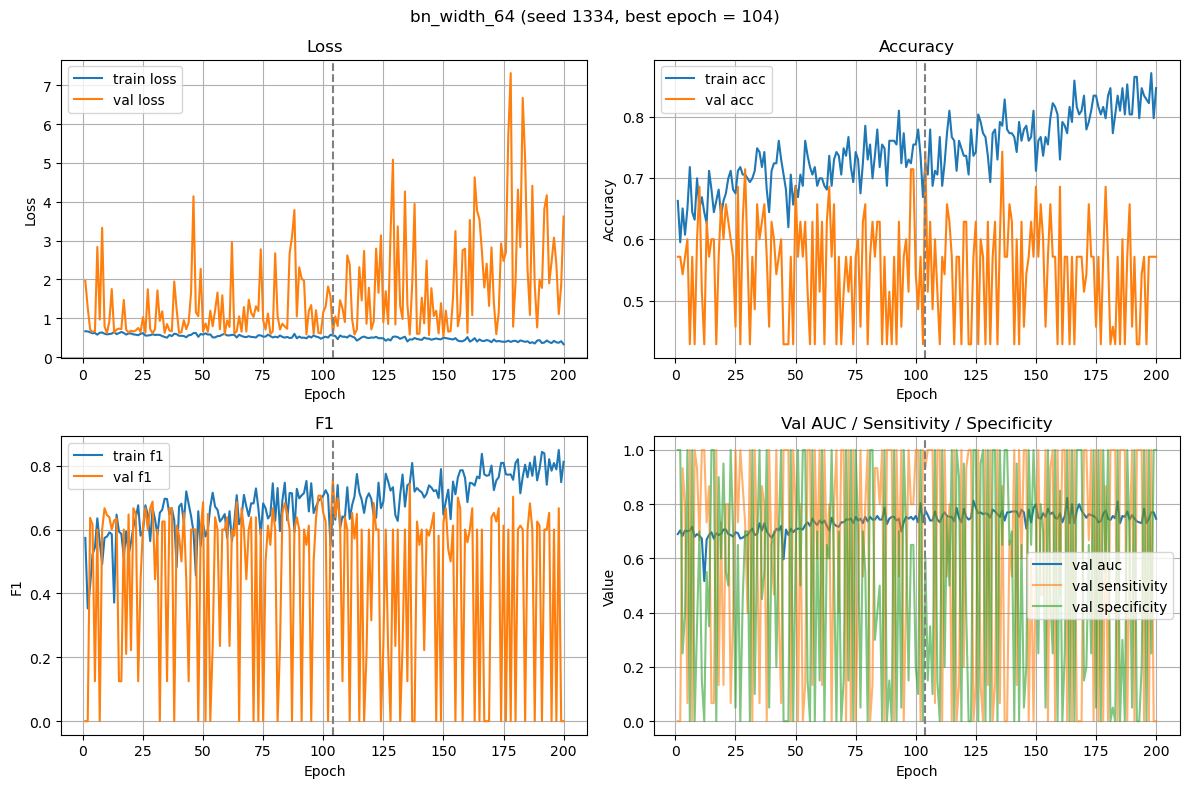

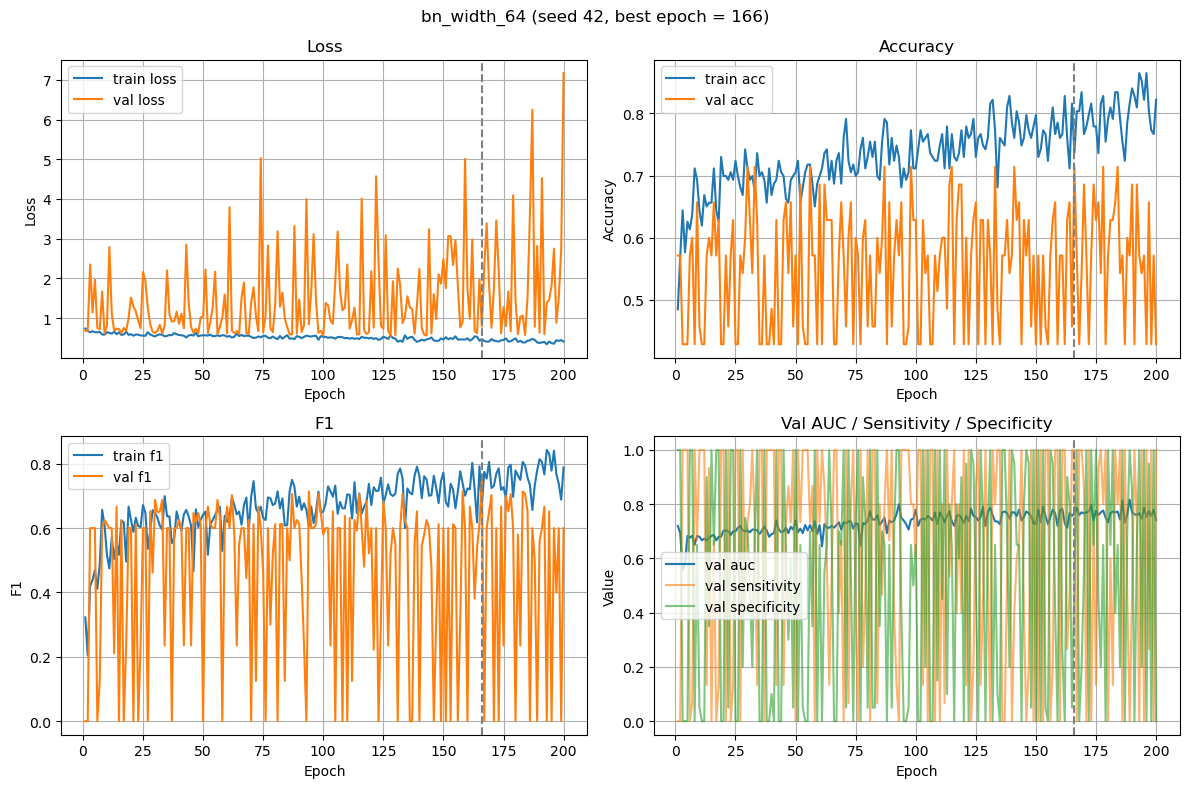

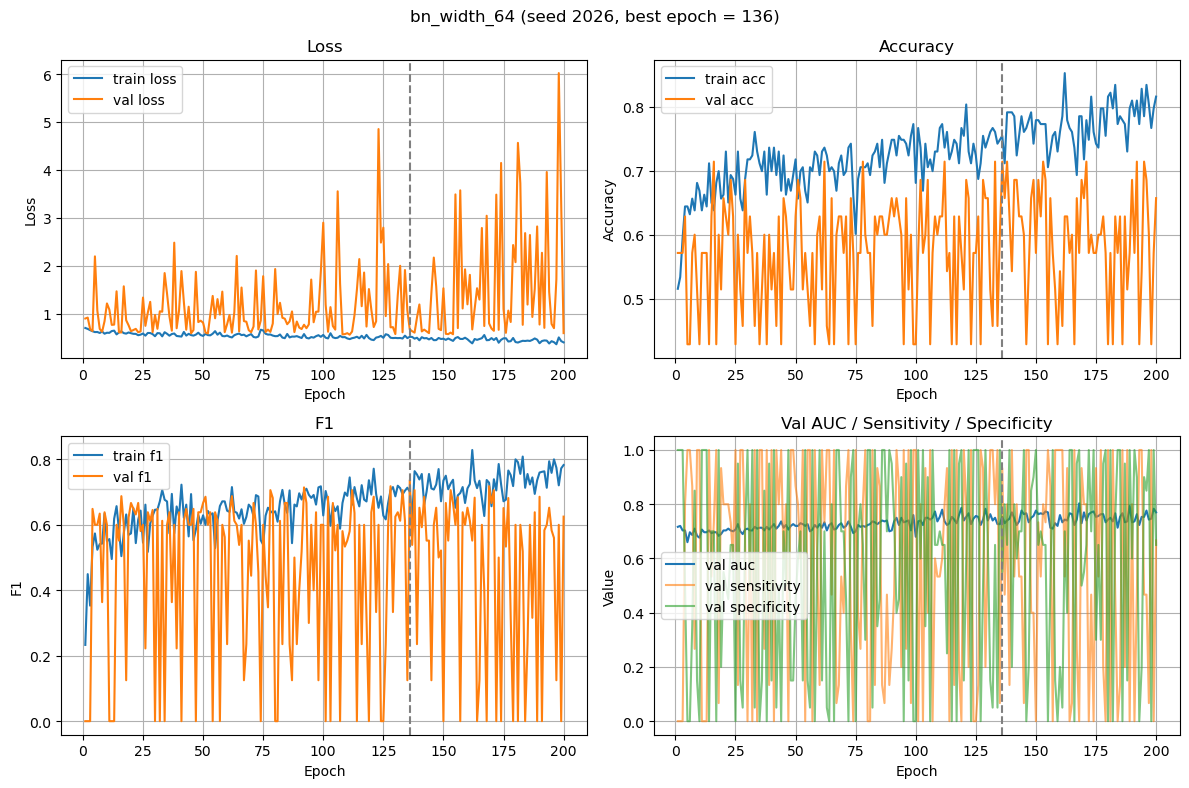

In [12]:
# กราฟ 2x2 ของแต่ละ seed ในแต่ละระดับ เก็บในโฟลเดอร์ figures ของระดับนั้น
for name in RUN_LIST:
    fig_dir = os.path.join(EXP_DIR, name, "figures")
    os.makedirs(fig_dir, exist_ok=True)

    for r in all_runs[name]:
        h = r["history"]
        best_epoch = r["best_epoch"]
        epochs_x = range(1, len(h["train_loss"]) + 1)

        plt.figure(figsize=(12, 8))

        plt.subplot(2, 2, 1)
        plt.plot(epochs_x, h["train_loss"], label="train loss")
        plt.plot(epochs_x, h["val_loss"], label="val loss")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("Loss")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 2)
        plt.plot(epochs_x, h["train_acc"], label="train acc")
        plt.plot(epochs_x, h["val_acc"], label="val acc")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Accuracy")
        plt.title("Accuracy")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 3)
        plt.plot(epochs_x, h["train_f1"], label="train f1")
        plt.plot(epochs_x, h["val_f1"], label="val f1")
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("F1")
        plt.title("F1")
        plt.grid(True)
        plt.legend()

        plt.subplot(2, 2, 4)
        plt.plot(epochs_x, h["val_auc"], label="val auc")
        plt.plot(epochs_x, h["val_sens"], label="val sensitivity", alpha=0.6)
        plt.plot(epochs_x, h["val_spec"], label="val specificity", alpha=0.6)
        plt.axvline(best_epoch, color="gray", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Value")
        plt.title("Val AUC / Sensitivity / Specificity")
        plt.grid(True)
        plt.legend()

        plt.suptitle(f"{name} (seed {r['seed']}, best epoch = {best_epoch})")
        plt.tight_layout()
        plt.savefig(os.path.join(fig_dir, f"curves_seed{r['seed']}.png"), dpi=150)
        plt.show()

## วิธีอ่านผล

## Test (ทำครั้งเดียว หลังเลือกโครงสร้างสุดท้ายจาก val แล้ว)

In [13]:
RUN_TEST = False          # เปลี่ยนเป็น True เมื่อเลือกระดับจาก val เสร็จแล้วเท่านั้น (ทำครั้งเดียว)
TEST_LEVEL = None         # ชื่อระดับที่เลือก เช่น "base"

if RUN_TEST:
    assert TEST_LEVEL in RUN_LIST, "ใส่ชื่อระดับที่เลือกใน TEST_LEVEL ก่อน"
    test_data = MRIDataset(test_ids, train=False)
    test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
    criterion = nn.CrossEntropyLoss()

    test_rows = []
    for SEED in SEEDS:
        pt = os.path.join(EXP_DIR, TEST_LEVEL, "models", f"seed{SEED}_best.pt")
        model = make_model(EXPERIMENTS[TEST_LEVEL]["MODEL"]).to(device)
        model.load_state_dict(torch.load(pt, map_location=device))      # น้ำหนักของ epoch ที่เลือกจาก val
        t = evaluate(model, test_loader, criterion)
        test_rows.append({"seed": SEED, **{m: t[m] for m in METRICS}, "TN": t["TN"], "FP": t["FP"], "FN": t["FN"], "TP": t["TP"]})

    test_table = pd.DataFrame(test_rows)
    display(test_table.round(3))

    print()
    print(f"ผลบน Test ของ {TEST_LEVEL} (mean ± SD ข้าม seed)")
    for m in METRICS:
        print(f"{m:12s}: {test_table[m].mean():.3f} ± {test_table[m].std(ddof=1):.3f}")

    test_table.to_csv(os.path.join(EXP_DIR, f"test_{TEST_LEVEL}.csv"), index=False)
else:
    print("ยังไม่เปิด test")

ยังไม่เปิด test
